Successfully connected to the database!
Found 30 segment(s) with images to display.

Segment 218401: Loaded array with shape (32, 32, 9)


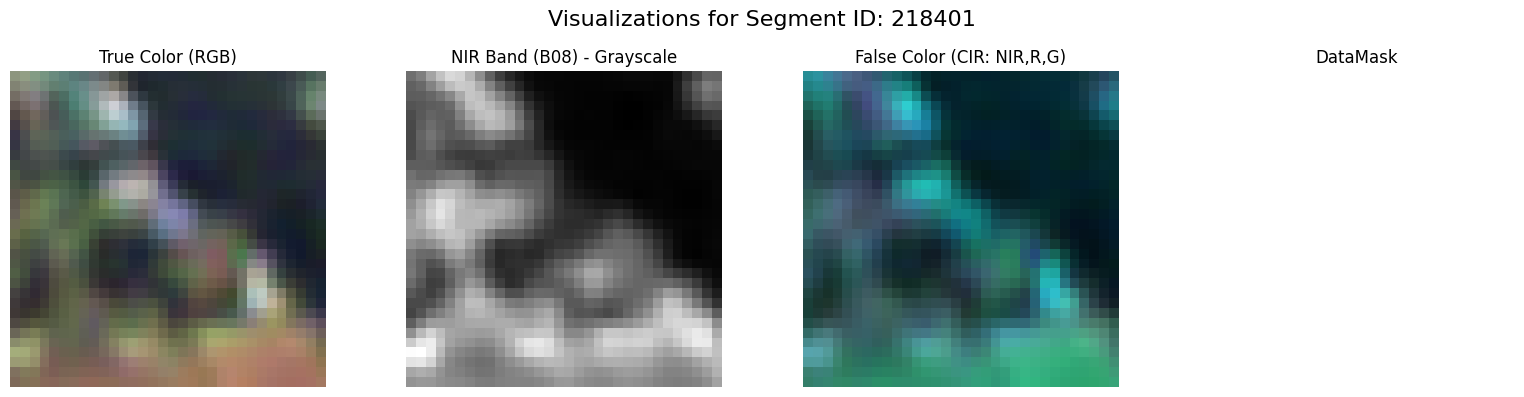


Segment 218392: Loaded array with shape (32, 32, 9)


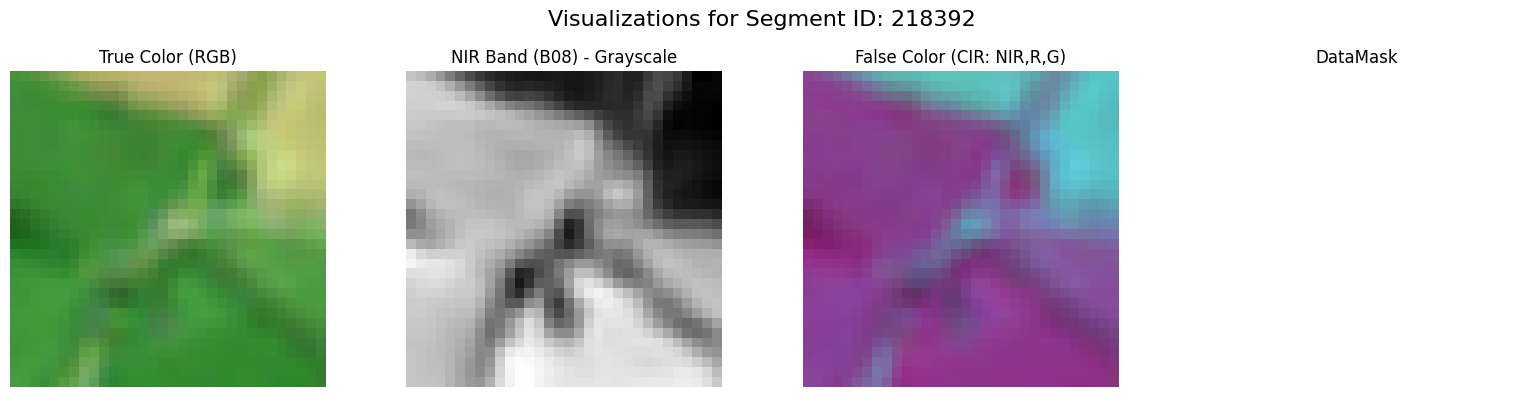


Segment 218391: Loaded array with shape (32, 32, 9)


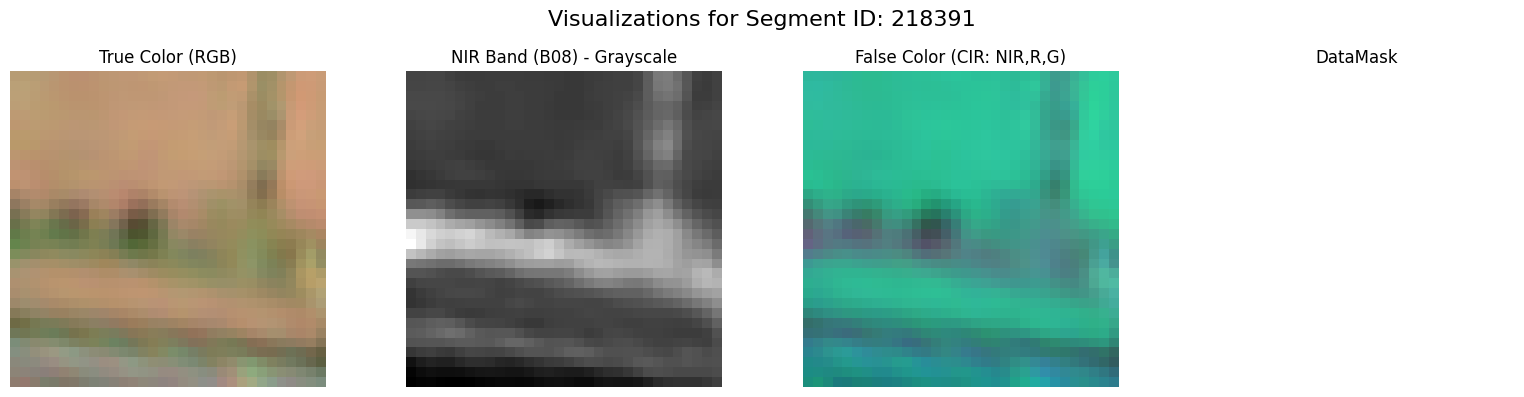


Segment 218389: Loaded array with shape (32, 32, 9)


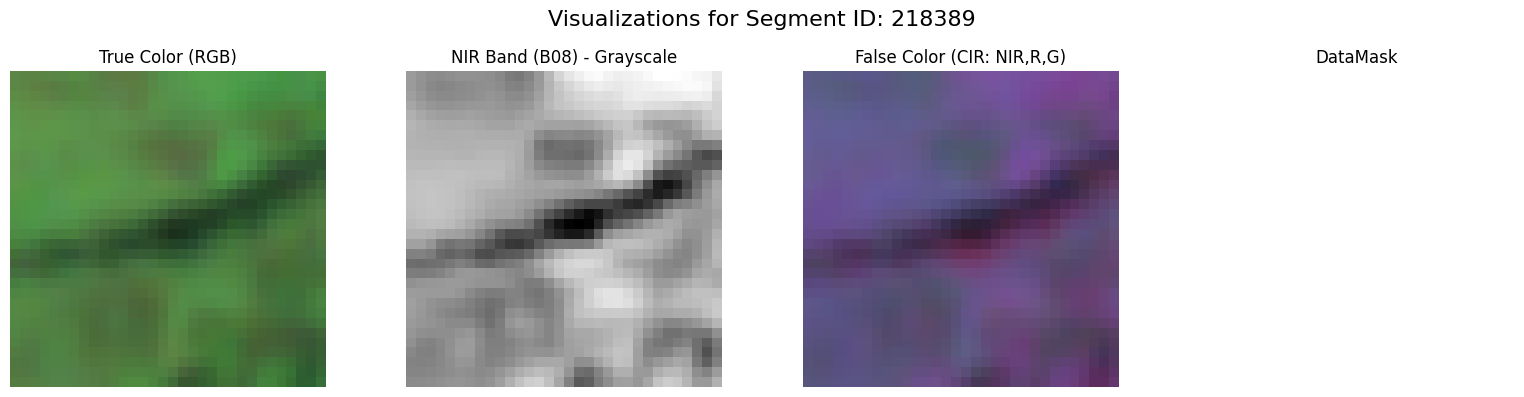


Segment 218387: Loaded array with shape (32, 32, 9)


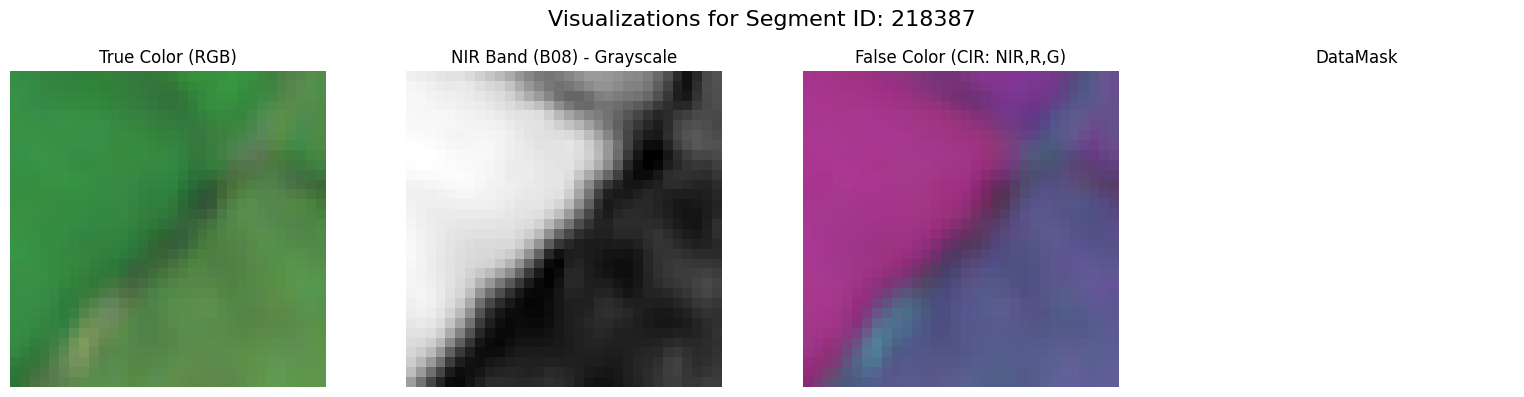


Segment 218386: Loaded array with shape (32, 32, 9)


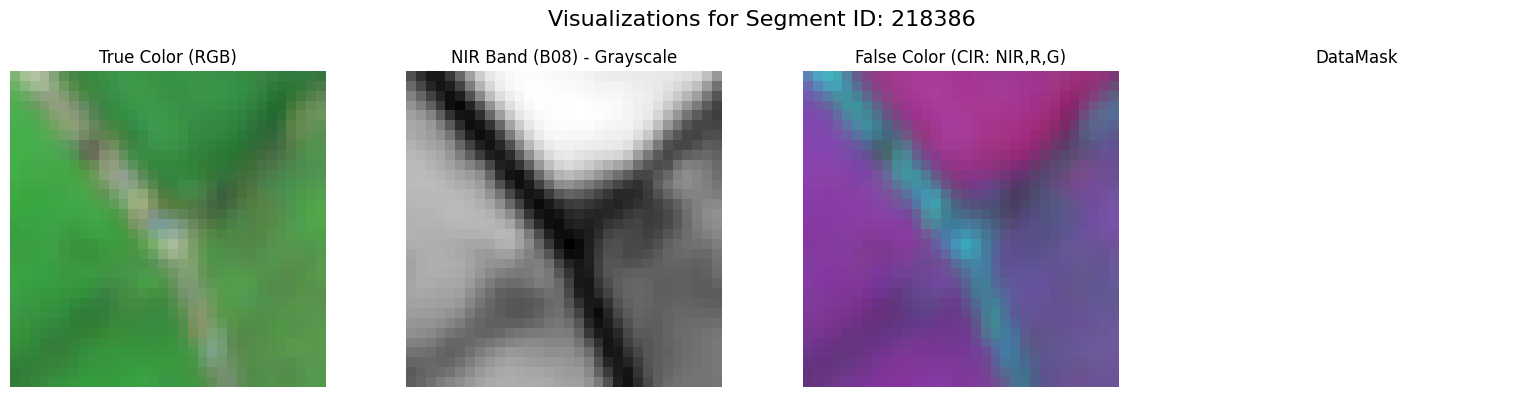


Segment 218383: Loaded array with shape (32, 32, 9)


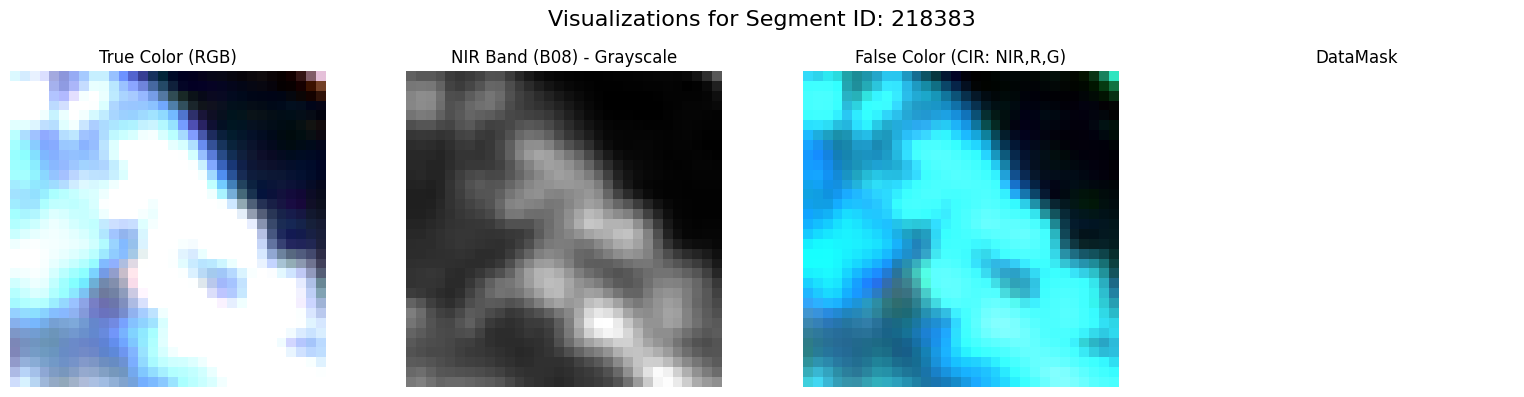


Segment 218380: Loaded array with shape (32, 32, 9)


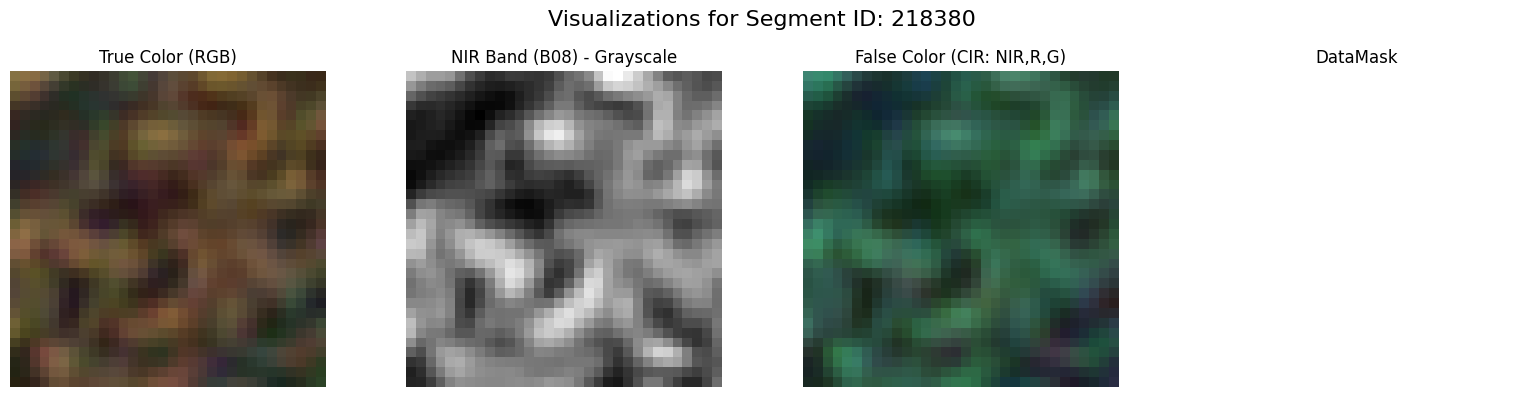


Segment 218379: Loaded array with shape (32, 32, 9)


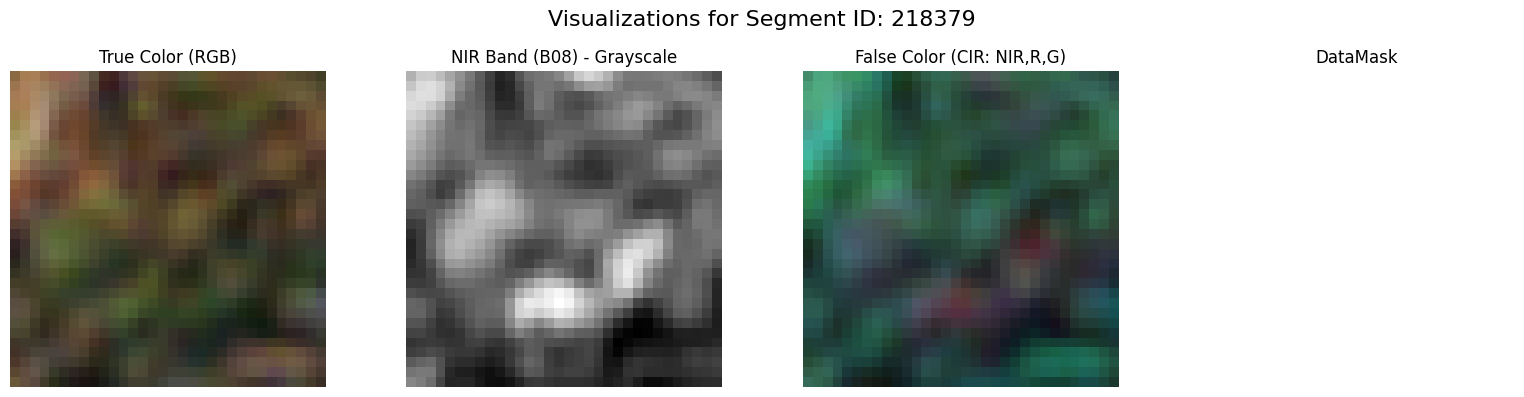


Segment 218378: Loaded array with shape (32, 32, 9)


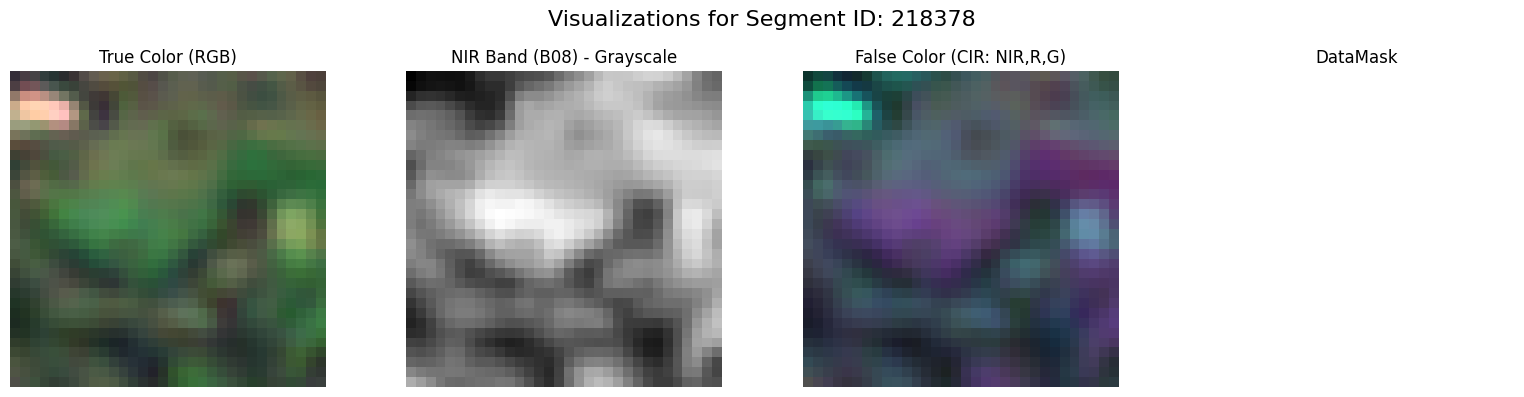


Segment 218377: Loaded array with shape (32, 32, 9)


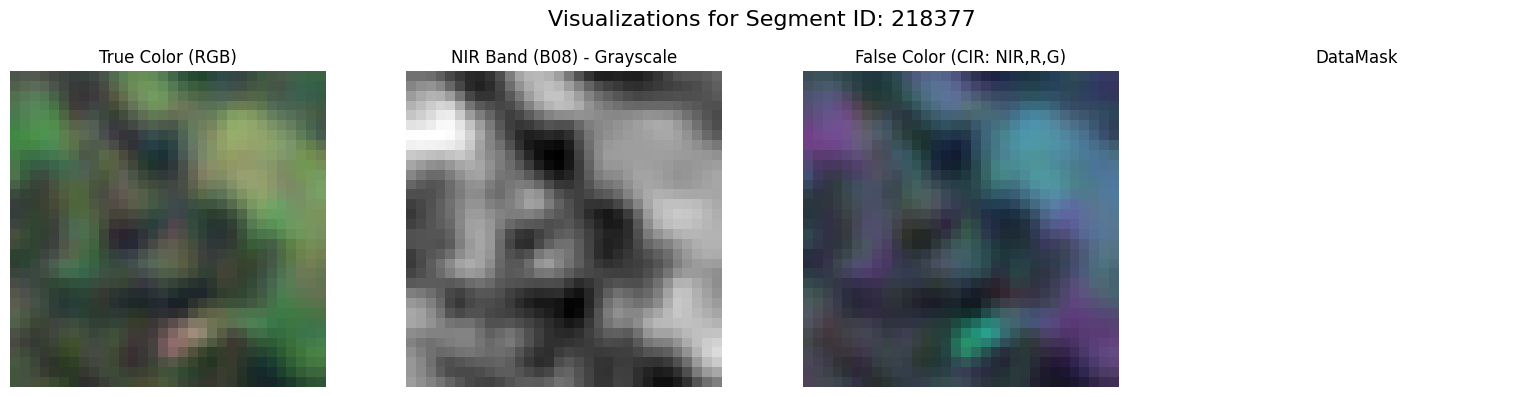


Segment 218376: Loaded array with shape (32, 32, 9)


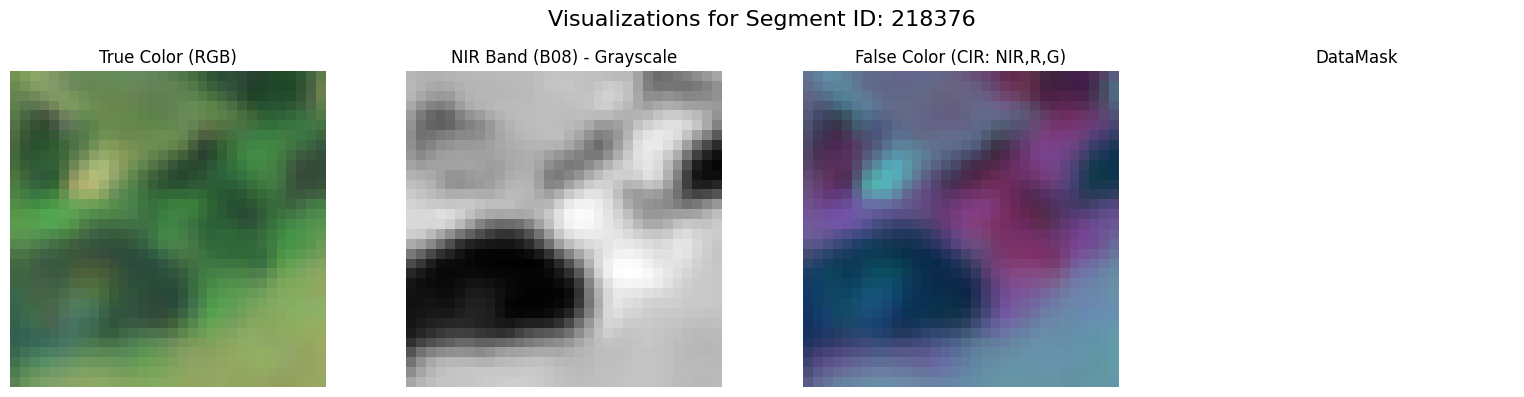


Segment 218373: Loaded array with shape (32, 32, 9)


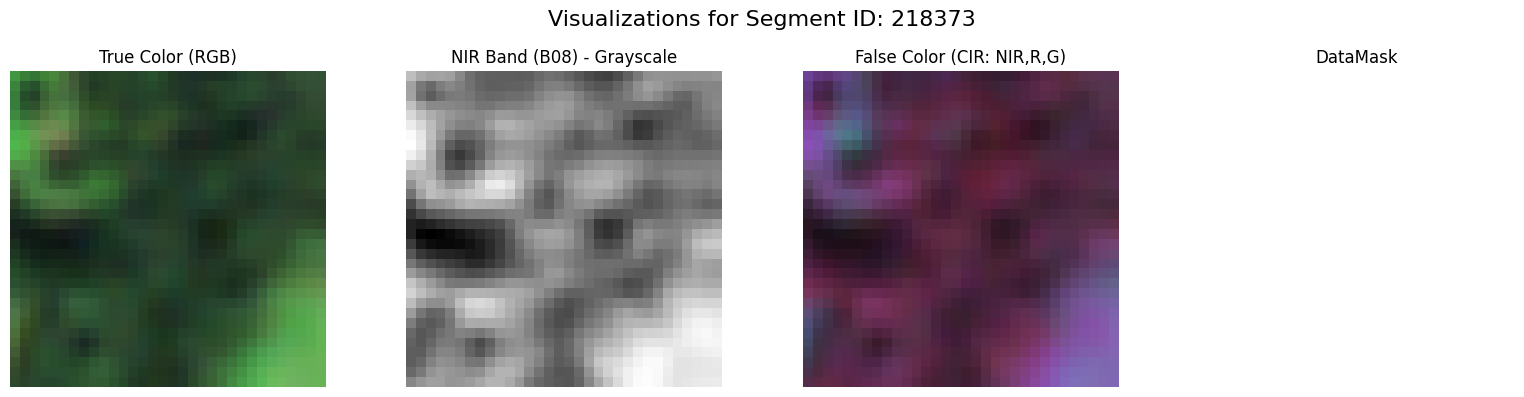


Segment 218372: Loaded array with shape (32, 32, 9)


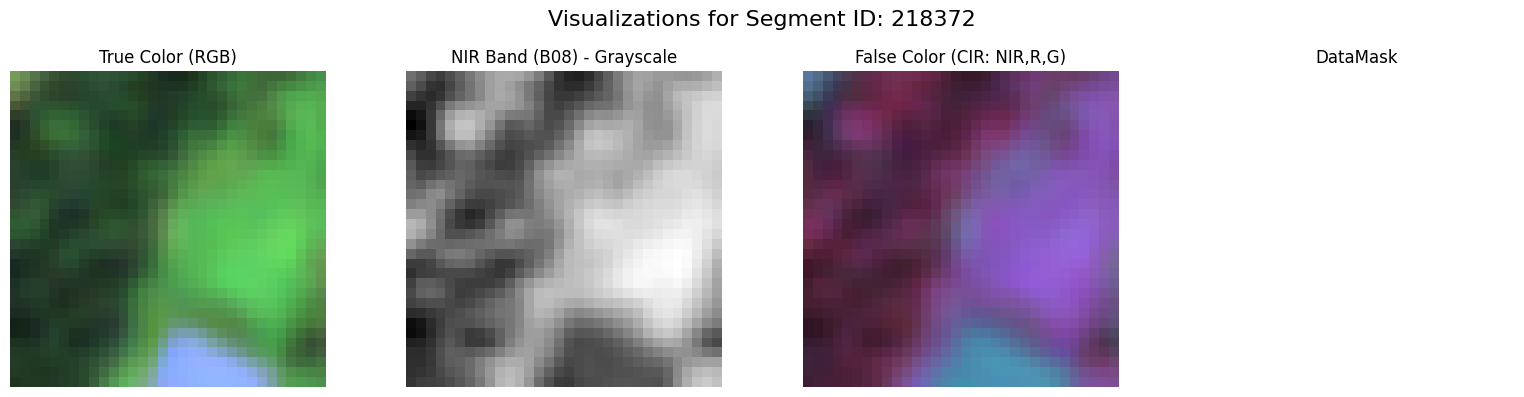


Segment 218365: Loaded array with shape (32, 32, 9)


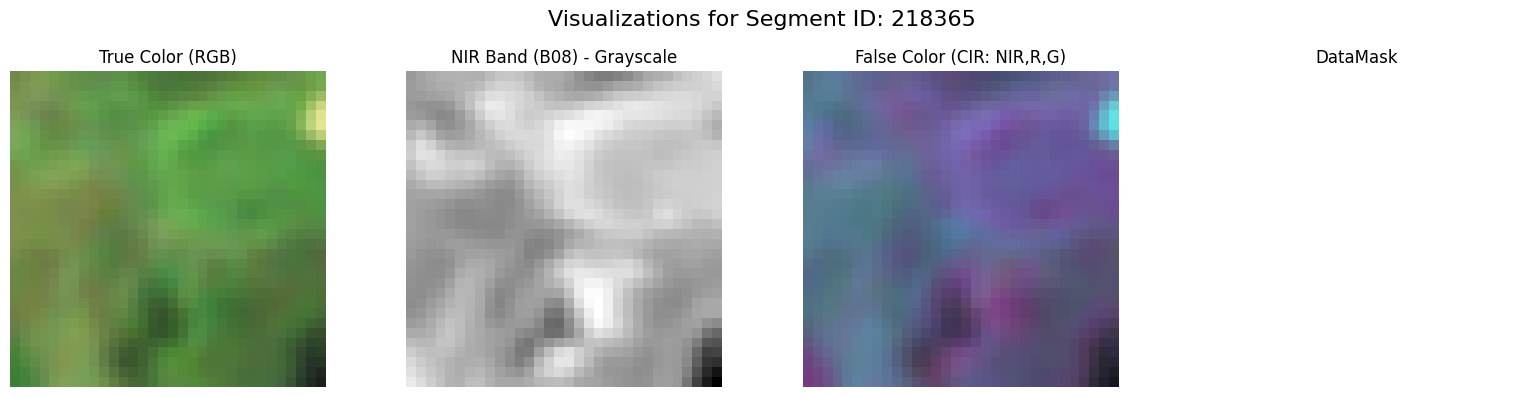


Segment 218363: Loaded array with shape (32, 32, 9)


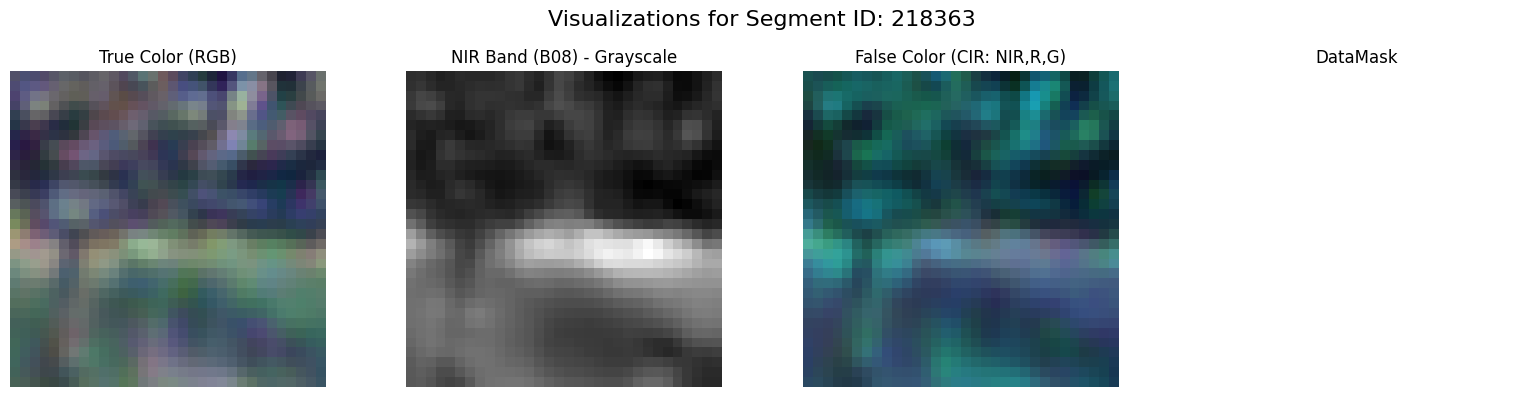


Segment 218362: Loaded array with shape (32, 32, 9)


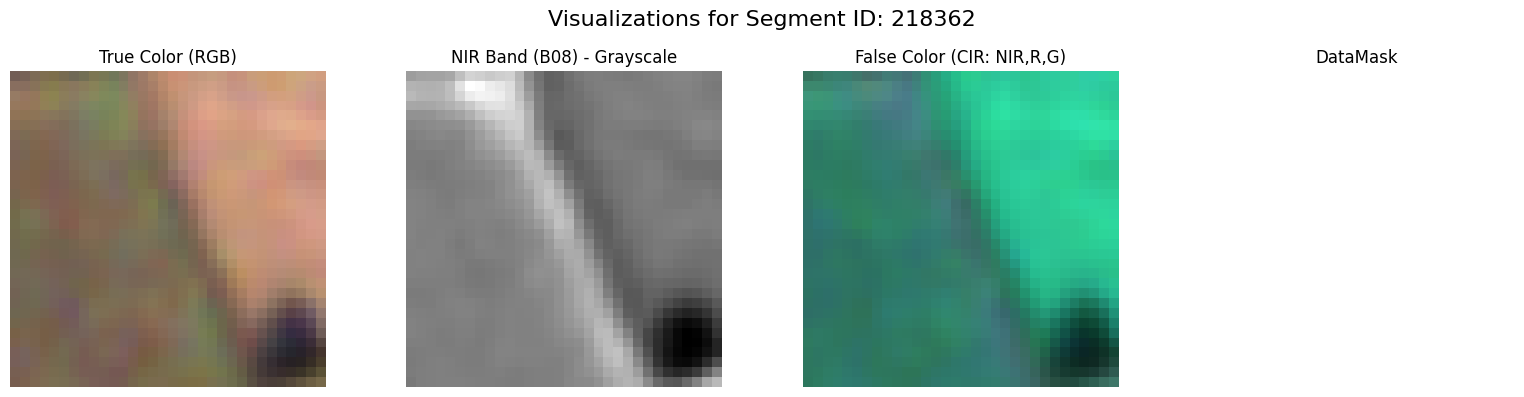


Segment 218355: Loaded array with shape (32, 32, 9)


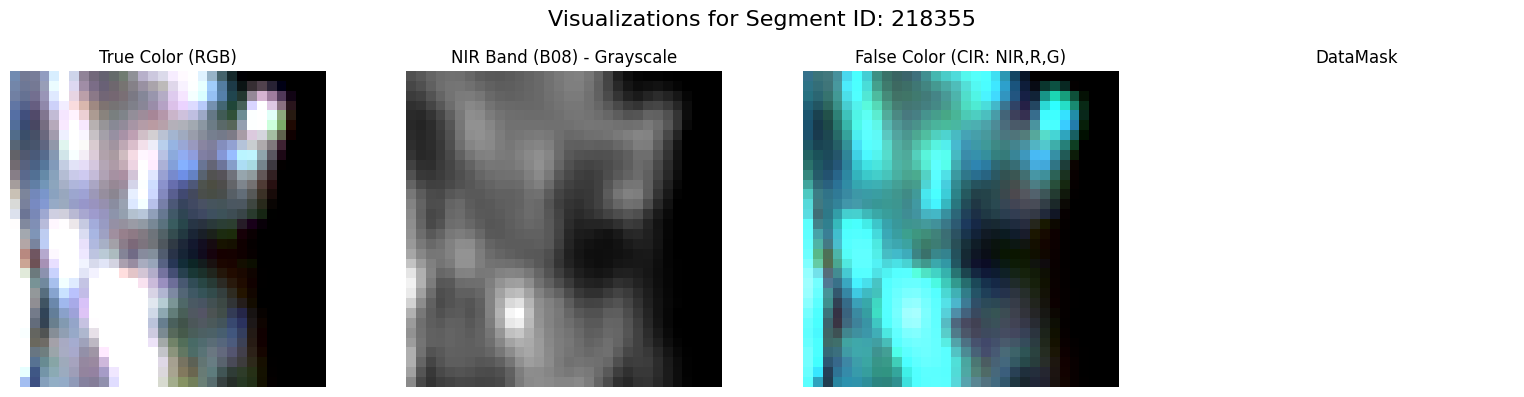


Segment 218353: Loaded array with shape (32, 32, 9)


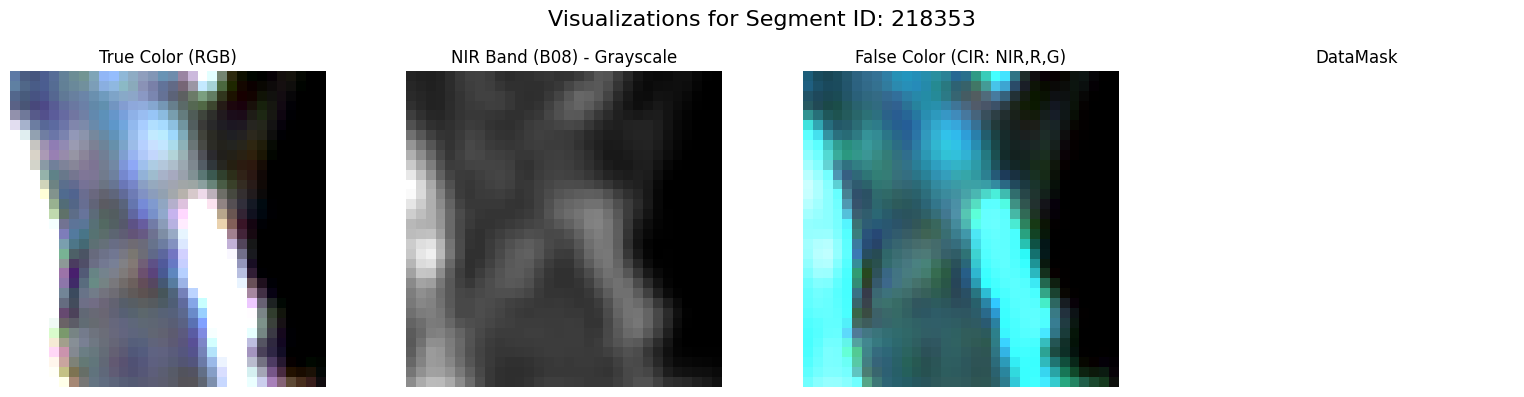


Segment 218351: Loaded array with shape (32, 32, 9)


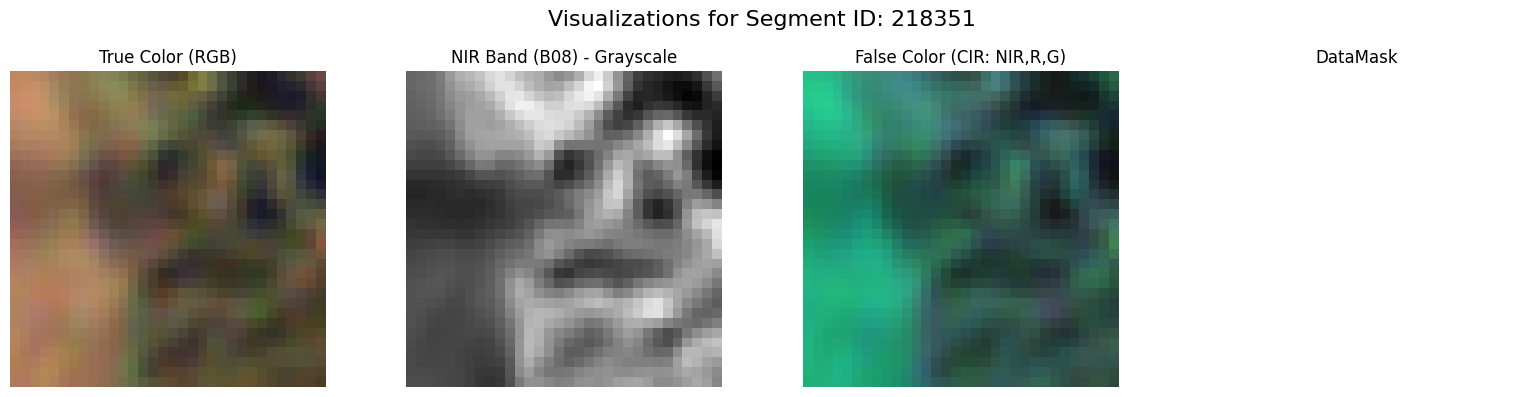


Segment 218349: Loaded array with shape (32, 32, 9)


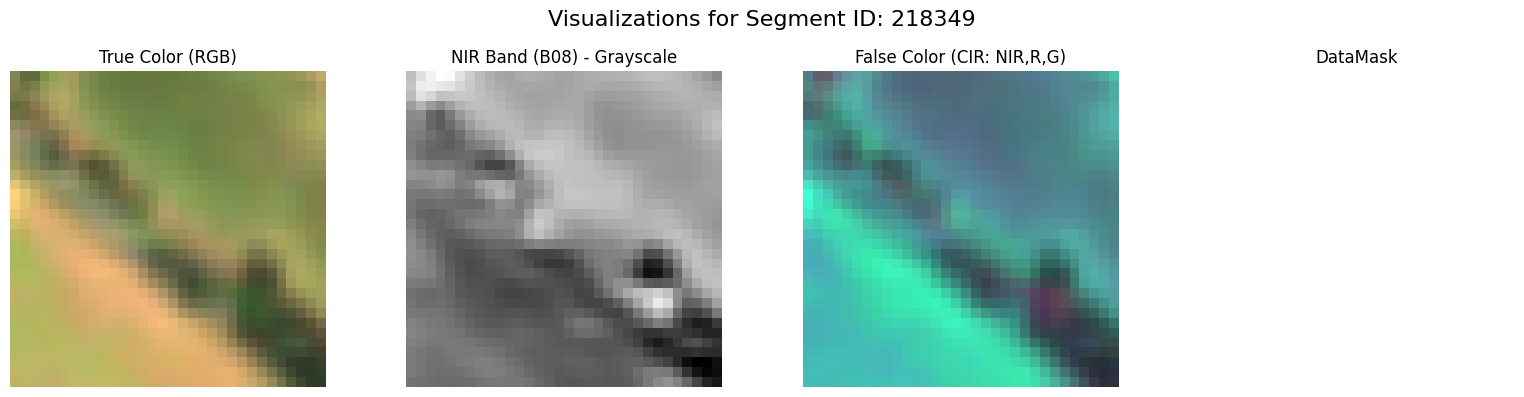


Segment 218342: Loaded array with shape (32, 32, 9)


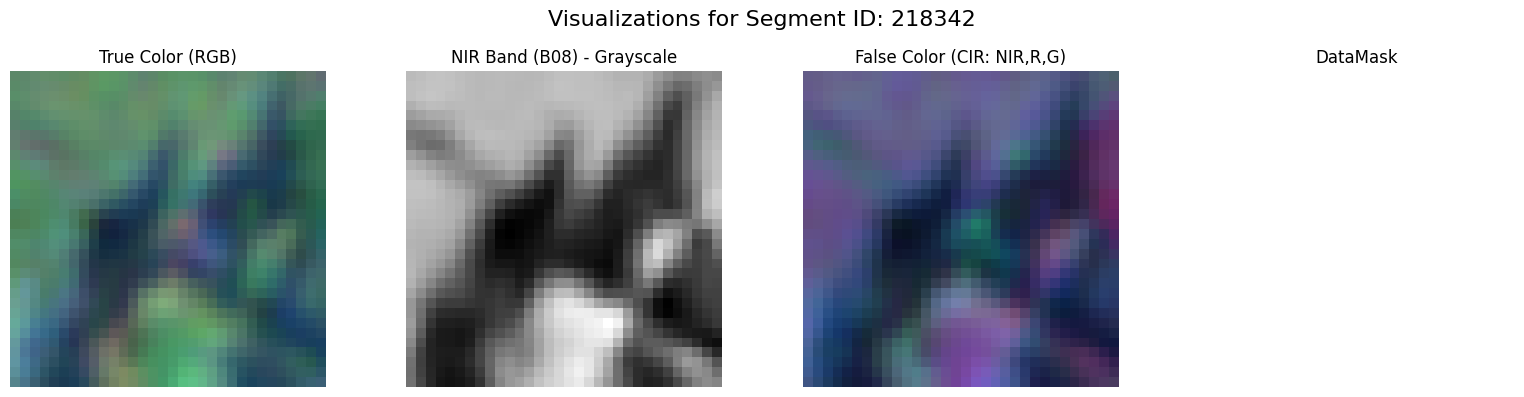


Segment 218338: Loaded array with shape (32, 32, 9)


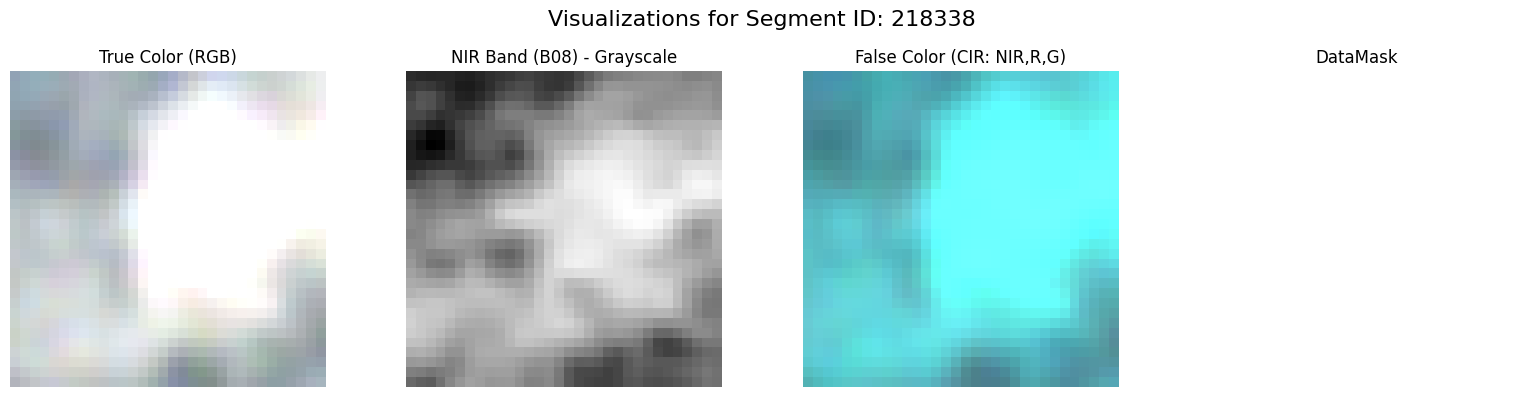


Segment 218333: Loaded array with shape (32, 32, 9)


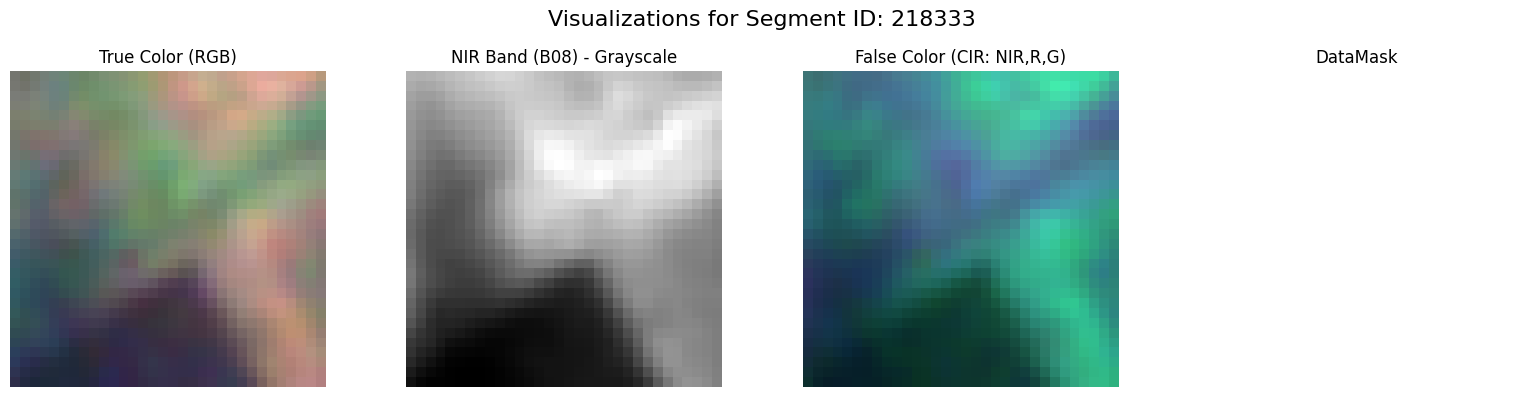


Segment 218328: Loaded array with shape (32, 32, 9)


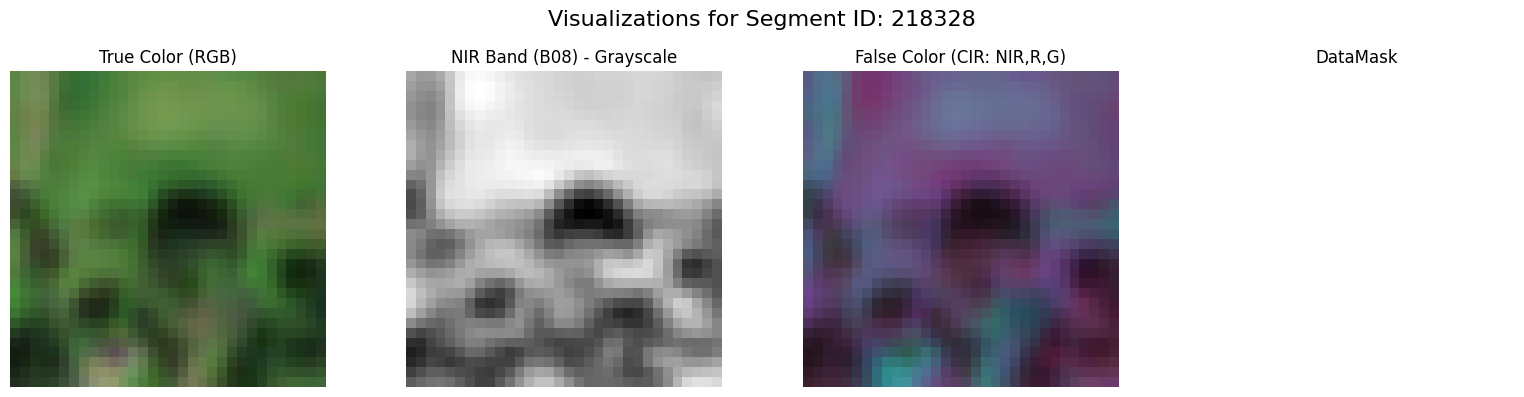


Segment 218327: Loaded array with shape (32, 32, 9)


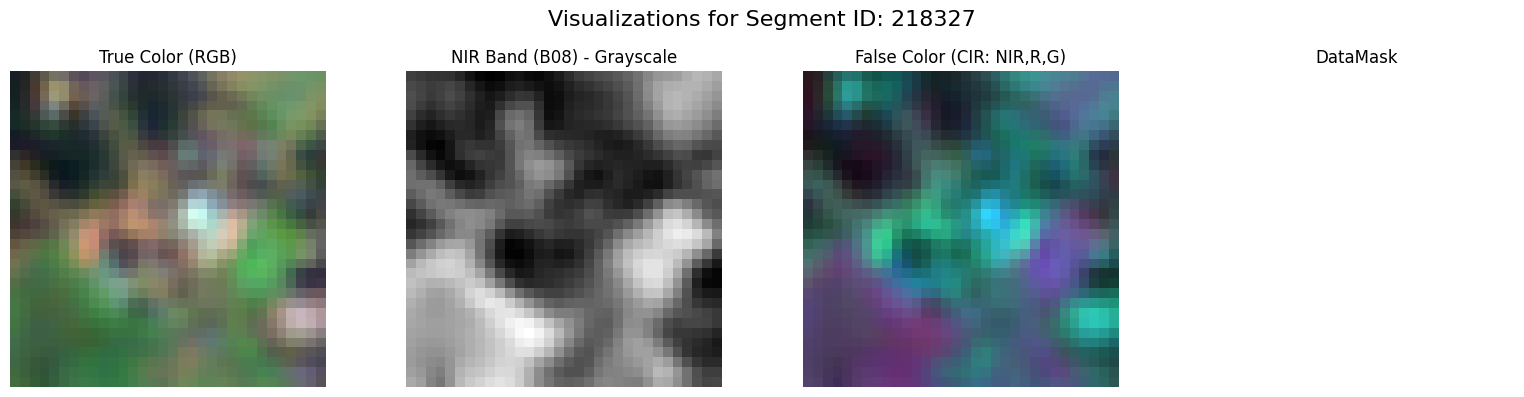


Segment 218326: Loaded array with shape (32, 32, 9)


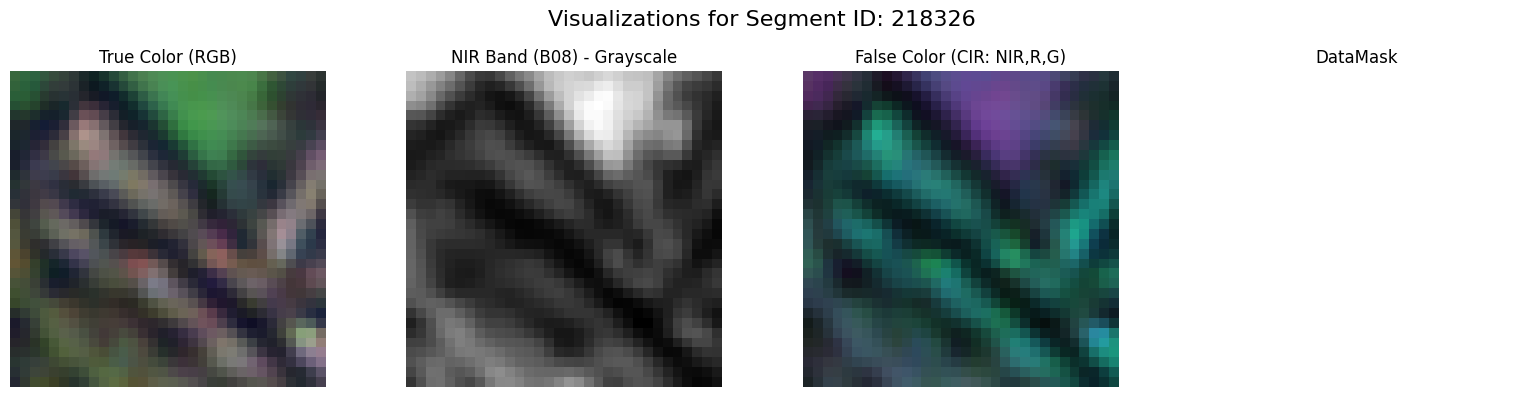


Segment 218325: Loaded array with shape (32, 32, 9)


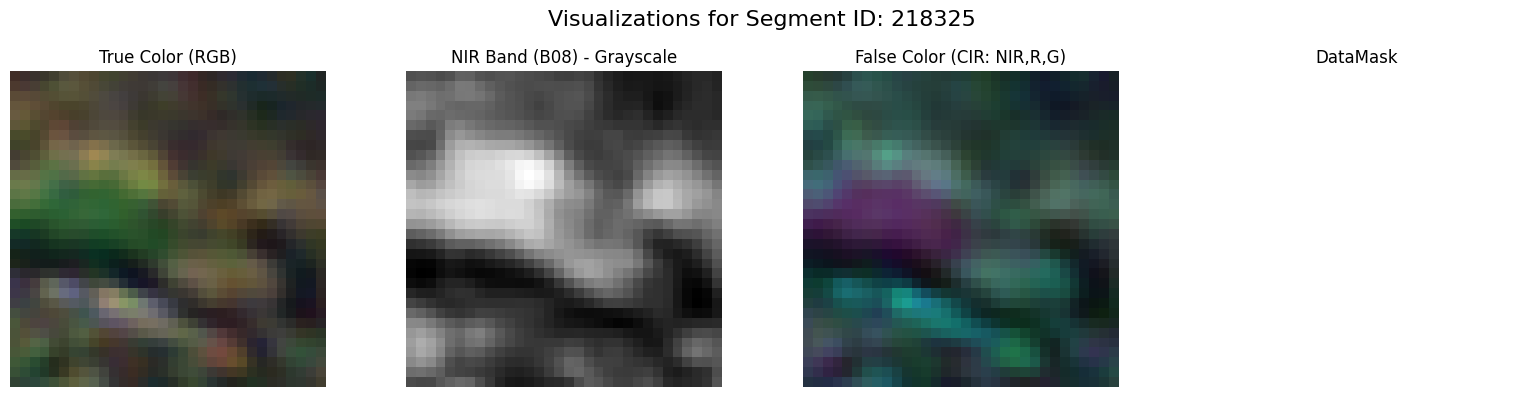


Segment 218320: Loaded array with shape (32, 32, 9)


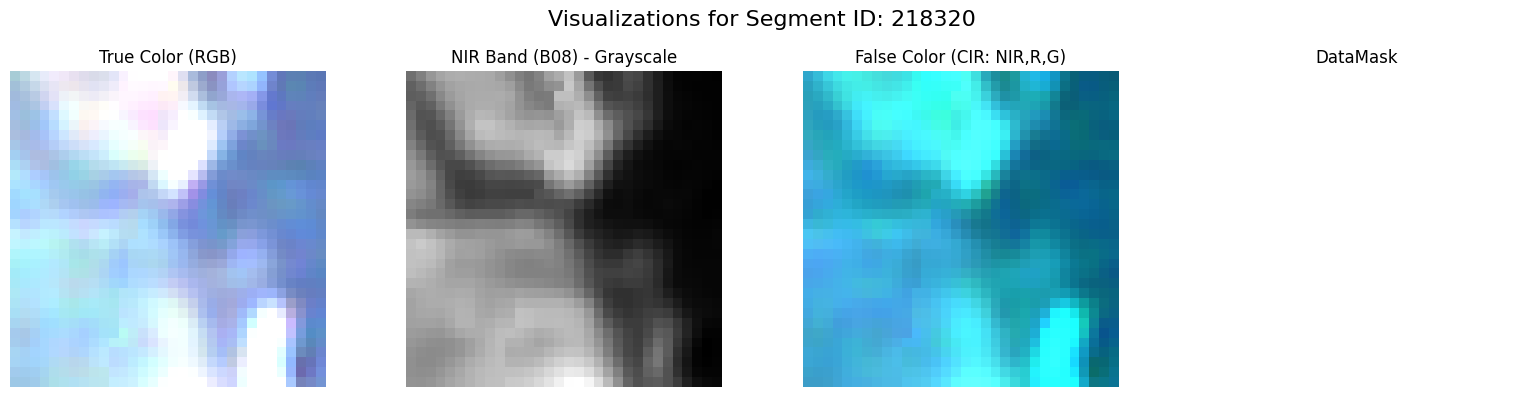


Segment 218319: Loaded array with shape (32, 32, 9)


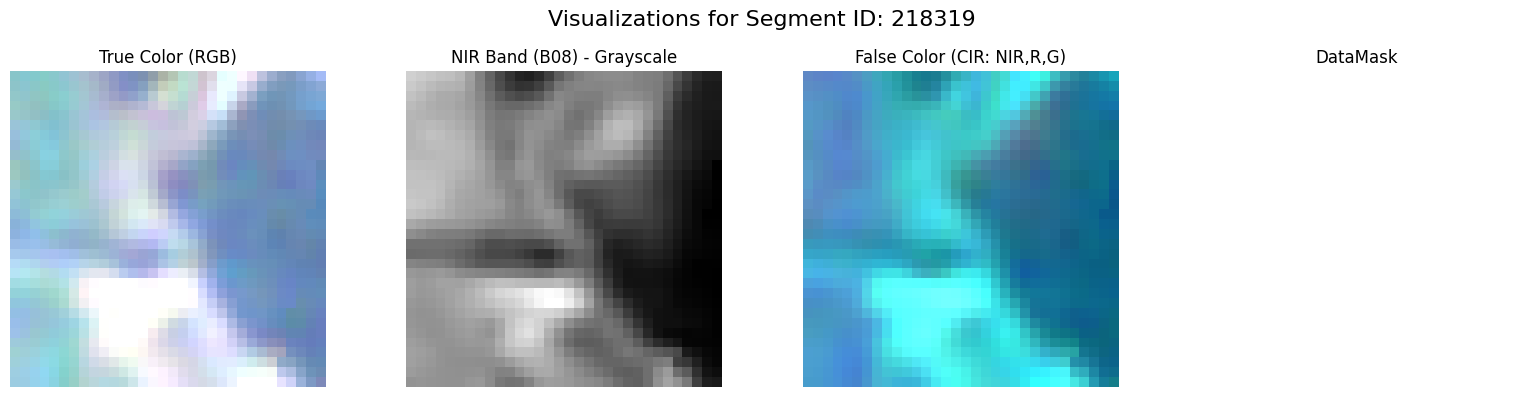

In [1]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

# 1. Create your database engine (replace with your actual connection string)
try:
    engine = create_engine('postgresql://markfinlay:@localhost:5432/osm')
    with engine.connect() as connection:
        print("Successfully connected to the database!")
except Exception as e:
    print(f"Error connecting to the database: {e}")
    raise

# 2. Query rows that have image data
query = "SELECT id, image_data FROM final_balanced_trail_segments WHERE image_data IS NOT NULL ORDER BY id DESC LIMIT 30" # Limit to 2 for quicker demo
try:
    segments_with_images = pd.read_sql(query, engine)
except Exception as e:
    print(f"Error executing SQL query: {e}")
    raise

if segments_with_images.empty:
    print("No segments with image_data found in the database (or matching the LIMIT).")
else:
    print(f"Found {len(segments_with_images)} segment(s) with images to display.")

    for idx, row in segments_with_images.iterrows():
        segment_id = row['id']
        image_bytes = row['image_data']

        if image_bytes is None:
            print(f"Segment {segment_id} has NULL image_data. Skipping.")
            continue

        try:
            image_array = np.load(io.BytesIO(image_bytes))
            print(f"\nSegment {segment_id}: Loaded array with shape {image_array.shape}")

            if not (image_array.ndim == 3 and image_array.shape[-1] == 9):
                print(f"  Segment {segment_id}: Image array has unexpected shape {image_array.shape}. Skipping visualizations for this segment.")
                continue

            # --- 1. True Color RGB (B04, B03, B02) ---
            # Bands 0, 1, 2 are Red, Green, Blue (already scaled by 8.0)
            rgb_bands = image_array[..., :3]
            true_color_image = np.clip(rgb_bands, 0, 1) # Normalize back to ~0-1

            # --- 2. Grayscale NIR Band (B08) ---
            # Band 5 is NIR (B08), not scaled by 8.0 in evalscript
            nir_band = image_array[..., 5]
            # Normalize NIR band (typically 0-1 reflectance) for display
            nir_gray_image = np.clip(nir_band, 0, 1)
            
            # --- 3. False-Color Composite (CIR: NIR, Red, Green) ---
            # Display R = NIR (band 5), G = Red (band 0), B = Green (band 1)
            
            # NIR band (B08) - already approx 0-1
            nir_for_cir = np.clip(image_array[..., 5], 0, 1)
            # Red band (B04*8.0) - normalize back to approx 0-1
            red_for_cir = np.clip(image_array[..., 0], 0, 1)
            # Green band (B03*8.0) - normalize back to approx 0-1
            green_for_cir = np.clip(image_array[..., 1], 0, 1)
            
            false_color_cir_image = np.stack([nir_for_cir, red_for_cir, green_for_cir], axis=-1)

            # --- 4. Grayscale dataMask ---
            # Band 8 is dataMask (0 for no-data, 1 for data)
            datamask_image = image_array[..., 8] # Values are 0 or 1

            # --- Plotting all visualizations ---
            fig, axs = plt.subplots(1, 4, figsize=(16, 4)) # 1 row, 4 columns of plots
            fig.suptitle(f"Visualizations for Segment ID: {segment_id}", fontsize=16)

            axs[0].imshow(true_color_image)
            axs[0].set_title("True Color (RGB)")
            axs[0].axis('off')

            axs[1].imshow(nir_gray_image, cmap='gray')
            axs[1].set_title("NIR Band (B08) - Grayscale")
            axs[1].axis('off')
            
            axs[2].imshow(false_color_cir_image)
            axs[2].set_title("False Color (CIR: NIR,R,G)")
            axs[2].axis('off')

            axs[3].imshow(datamask_image, cmap='gray', vmin=0, vmax=1) # Ensure correct display for 0-1 mask
            axs[3].set_title("DataMask")
            axs[3].axis('off')
            
            plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout to make space for suptitle
            plt.show()

        except Exception as e:
            print(f"  Error processing or displaying images for segment {segment_id}: {e}")